# Réplica en pandas del flujo de datos Gen2

El flujo de transformación del entregable 2 está escrito en **Power Query M** ([`../dataflow/`](../dataflow/)) y solo se ejecuta dentro de Microsoft Fabric. Este cuaderno reproduce **paso a paso la misma lógica** con pandas, por dos motivos:

1. **Comprobar** que las transformaciones hacen lo que se espera antes de llevarlas a Fabric.
2. **Obtener los resultados esperados** (filas, totales, claves) y guardarlos en [`../datos-esperados/`](../datos-esperados/). Al ejecutar el flujo en Fabric, sus tablas deben coincidir con estas; el cuaderno de validación las compara.

Cada sección indica el archivo `.m` que replica.

*Datos: `orders.csv`, `customers.csv` y `products.csv` del repositorio [dp-data](https://github.com/MicrosoftLearning/dp-data) de Microsoft Learning (licencia MIT), los mismos que usa el laboratorio.*

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

DATOS = '../datasets'
SALIDA = '../datos-esperados'

## `dim_producto.m`

In [2]:
productos = pd.read_csv(f'{DATOS}/products.csv', dtype={'ProductID': 'int64', 'ListPrice': 'float64'})
productos['ProductName'] = productos['ProductName'].str.strip()
productos['Category'] = productos['Category'].str.strip()
dim_producto = productos.drop_duplicates('ProductID')
print(f'dim_producto: {len(dim_producto)} filas · {dim_producto["Category"].nunique()} categorías')
dim_producto.head()

dim_producto: 295 filas · 37 categorías


,ProductID,ProductName,Category,ListPrice
0,771,"Mountain-100 Silver, 38",Mountain Bikes,3399.99
1,772,"Mountain-100 Silver, 42",Mountain Bikes,3399.99
2,773,"Mountain-100 Silver, 44",Mountain Bikes,3399.99
3,774,"Mountain-100 Silver, 48",Mountain Bikes,3399.99
4,775,"Mountain-100 Black, 38",Mountain Bikes,3374.99


## `dim_cliente.m`

Se construye el nombre completo y se extrae el dominio del correo. El correo completo **no se publica**: es un dato personal y los flujos de datos no admiten seguridad de nivel de fila.

In [3]:
clientes = pd.read_csv(f'{DATOS}/customers.csv')
clientes['CustomerName'] = clientes['FirstName'].str.strip() + ' ' + clientes['LastName'].str.strip()
clientes['EmailDomain'] = clientes['EmailAddress'].str.split('@').str[1]
dim_cliente = clientes[['CustomerID', 'CustomerName', 'EmailDomain']].drop_duplicates('CustomerID')
print(f'dim_cliente: {len(dim_cliente)} filas · dominios: {dim_cliente["EmailDomain"].value_counts().to_dict()}')
dim_cliente.head()

dim_cliente: 847 filas · dominios: {'adventure-works.com': 847}


,CustomerID,CustomerName,EmailDomain
0,1,Orlando Gee,adventure-works.com
1,2,Keith Harris,adventure-works.com
2,3,Donna Carreras,adventure-works.com
3,4,Janet Gates,adventure-works.com
4,5,Lucy Harrington,adventure-works.com


## `fact_ventas.m`

Tipos, eliminación de duplicados por la clave natural (pedido + línea), filtro de filas inválidas, la columna `MonthNo` del laboratorio y tres columnas más: año, precio unitario y clave de fecha.

In [4]:
pedidos = pd.read_csv(f'{DATOS}/orders.csv', parse_dates=['OrderDate'])
filas_origen = len(pedidos)

fact = pedidos.drop_duplicates(['SalesOrderID', 'LineItem'])
duplicados = filas_origen - len(fact)
fact = fact[fact['OrderDate'].notna() & (fact['OrderQty'] > 0) & (fact['LineItemTotal'] >= 0)]
invalidas = filas_origen - duplicados - len(fact)

fact = fact.assign(
    MonthNo=fact['OrderDate'].dt.month,
    Year=fact['OrderDate'].dt.year,
    UnitPrice=(fact['LineItemTotal'] / fact['OrderQty']).round(2),
    DateKey=fact['OrderDate'].dt.strftime('%Y%m%d').astype(int),
)
print(f'Origen: {filas_origen} · duplicados: {duplicados} · inválidas: {invalidas} · fact_ventas: {len(fact)} filas')
print(f'Pedidos: {fact["SalesOrderID"].nunique()} · clientes: {fact["CustomerID"].nunique()} · productos: {fact["ProductID"].nunique()}')
print(f'Fechas: {fact["OrderDate"].min().date()} → {fact["OrderDate"].max().date()} · ventas totales: {fact["LineItemTotal"].sum():,.2f}')
fact.head()

Origen: 542 · duplicados: 0 · inválidas: 0 · fact_ventas: 542 filas
Pedidos: 32 · clientes: 32 · productos: 142
Fechas: 2022-06-01 → 2022-12-01 · ventas totales: 708,690.07


,SalesOrderID,OrderDate,CustomerID,LineItem,ProductID,OrderQty,LineItemTotal,MonthNo,Year,UnitPrice,DateKey
0,71774,2022-06-01,29847,1,836,1,356.90,6,2022,356.90,20220601
1,71774,2022-06-01,29847,2,822,1,356.90,6,2022,356.90,20220601
2,71776,2022-06-01,30072,1,907,1,63.90,6,2022,63.90,20220601
3,71780,2022-06-01,30113,1,905,4,873.82,6,2022,218.46,20220601
4,71780,2022-06-01,30113,2,983,2,923.39,6,2022,461.70,20220601


## `dim_fecha.m`

Una dimensión de fecha **generada**, no leída de ningún archivo. Es el ejemplo que da el curso de las ventajas de un flujo de datos: una tabla estándar y coherente que todos los informes reutilizan. Cubre los años completos con ventas.

In [5]:
inicio = pd.Timestamp(fact['OrderDate'].min().year, 1, 1)
fin = pd.Timestamp(fact['OrderDate'].max().year, 12, 31)
fechas = pd.date_range(inicio, fin, freq='D')
MESES = ['enero', 'febrero', 'marzo', 'abril', 'mayo', 'junio', 'julio', 'agosto', 'septiembre', 'octubre', 'noviembre', 'diciembre']
DIAS = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']
dim_fecha = pd.DataFrame({
    'Date': fechas.date,
    'DateKey': fechas.strftime('%Y%m%d').astype(int),
    'Year': fechas.year,
    'Quarter': 'T' + fechas.quarter.astype(str),
    'MonthNo': fechas.month,
    'MonthName': [MESES[m - 1] for m in fechas.month],
    'DayOfWeek': fechas.dayofweek + 1,
    'DayName': [DIAS[d] for d in fechas.dayofweek],
    'IsWeekend': fechas.dayofweek >= 5,
})
print(f'dim_fecha: {len(dim_fecha)} filas ({dim_fecha["Date"].min()} → {dim_fecha["Date"].max()})')
dim_fecha.head()

dim_fecha: 365 filas (2022-01-01 → 2022-12-31)


,Date,DateKey,Year,Quarter,MonthNo,MonthName,DayOfWeek,DayName,IsWeekend
0,2022-01-01,20220101,2022,T1,1,enero,6,sábado,True
1,2022-01-02,20220102,2022,T1,1,enero,7,domingo,True
2,2022-01-03,20220103,2022,T1,1,enero,1,lunes,False
3,2022-01-04,20220104,2022,T1,1,enero,2,martes,False
4,2022-01-05,20220105,2022,T1,1,enero,3,miércoles,False


## `ventas_mensuales.m`

Hace **referencia** a `fact_ventas` (no vuelve a leer el CSV) y la **combina** con `dim_producto` para traer la categoría. Agrupa por año, mes y categoría.

In [6]:
ventas_mensuales = (fact.merge(dim_producto[['ProductID', 'Category']], on='ProductID', how='left')
                   .groupby(['Year', 'MonthNo', 'Category'], as_index=False)
                   .agg(Pedidos=('SalesOrderID', 'nunique'), Unidades=('OrderQty', 'sum'), Ventas=('LineItemTotal', 'sum')))
ventas_mensuales['Ventas'] = ventas_mensuales['Ventas'].round(2)
ventas_mensuales = ventas_mensuales.sort_values(['Year', 'MonthNo', 'Ventas'], ascending=[True, True, False]).reset_index(drop=True)
print(f'ventas_mensuales: {len(ventas_mensuales)} filas · {ventas_mensuales["Category"].nunique()} categorías · '
      f'{ventas_mensuales[["Year", "MonthNo"]].drop_duplicates().shape[0]} meses')
ventas_mensuales.head(10)

ventas_mensuales: 122 filas · 26 categorías · 7 meses


,Year,MonthNo,Category,Pedidos,Unidades,Ventas
0,2022,6,Touring Bikes,3,165,145280.66
1,2022,6,Road Bikes,1,69,51096.06
2,2022,6,Mountain Bikes,1,44,25125.72
3,2022,6,Touring Frames,3,38,18463.92
4,2022,6,Road Frames,2,26,10745.70
5,2022,6,Mountain Frames,1,11,3937.58
6,2022,6,Jerseys,3,116,3529.08
7,2022,6,Vests,3,66,2327.59
8,2022,6,Helmets,3,76,1529.43
9,2022,6,Hydration Packs,4,28,923.84


## Comprobaciones de integridad

Lo que después validará el cuaderno de Fabric sobre las tablas del lakehouse.

In [7]:
comprobaciones = {
    'Sin duplicados en la clave de fact_ventas': not fact.duplicated(['SalesOrderID', 'LineItem']).any(),
    'Todos los productos de fact_ventas existen en dim_producto': fact['ProductID'].isin(dim_producto['ProductID']).all(),
    'Todos los clientes de fact_ventas existen en dim_cliente': fact['CustomerID'].isin(dim_cliente['CustomerID']).all(),
    'Todas las fechas de fact_ventas existen en dim_fecha': fact['DateKey'].isin(dim_fecha['DateKey']).all(),
    'ventas_mensuales suma lo mismo que fact_ventas': round(ventas_mensuales['Ventas'].sum(), 2) == round(fact['LineItemTotal'].sum(), 2),
}
for nombre, ok in comprobaciones.items():
    print(f"{'[OK]   ' if ok else '[FALLO]'} {nombre}")

[OK]    Sin duplicados en la clave de fact_ventas
[OK]    Todos los productos de fact_ventas existen en dim_producto
[OK]    Todos los clientes de fact_ventas existen en dim_cliente
[OK]    Todas las fechas de fact_ventas existen en dim_fecha
[OK]    ventas_mensuales suma lo mismo que fact_ventas


## Resultado esperado

Se guardan las cinco tablas y un resumen con los valores de control.

In [8]:
tablas = {'fact_ventas': fact.assign(OrderDate=fact['OrderDate'].dt.date), 'dim_producto': dim_producto,
          'dim_cliente': dim_cliente, 'dim_fecha': dim_fecha, 'ventas_mensuales': ventas_mensuales}
for nombre, df in tablas.items():
    df.to_csv(f'{SALIDA}/{nombre}.csv', index=False)

control = pd.DataFrame([
    {'tabla': 'fact_ventas', 'filas': len(fact), 'control': 'suma LineItemTotal', 'valor': round(fact['LineItemTotal'].sum(), 2)},
    {'tabla': 'dim_producto', 'filas': len(dim_producto), 'control': 'productos distintos', 'valor': dim_producto['ProductID'].nunique()},
    {'tabla': 'dim_cliente', 'filas': len(dim_cliente), 'control': 'clientes distintos', 'valor': dim_cliente['CustomerID'].nunique()},
    {'tabla': 'dim_fecha', 'filas': len(dim_fecha), 'control': 'días', 'valor': len(dim_fecha)},
    {'tabla': 'ventas_mensuales', 'filas': len(ventas_mensuales), 'control': 'suma Ventas', 'valor': round(ventas_mensuales['Ventas'].sum(), 2)},
])
control.to_csv(f'{SALIDA}/valores-control.csv', index=False)
control

,tabla,filas,control,valor
0,fact_ventas,542,suma LineItemTotal,708690.07
1,dim_producto,295,productos distintos,295.00
2,dim_cliente,847,clientes distintos,847.00
3,dim_fecha,365,días,365.00
4,ventas_mensuales,122,suma Ventas,708690.07


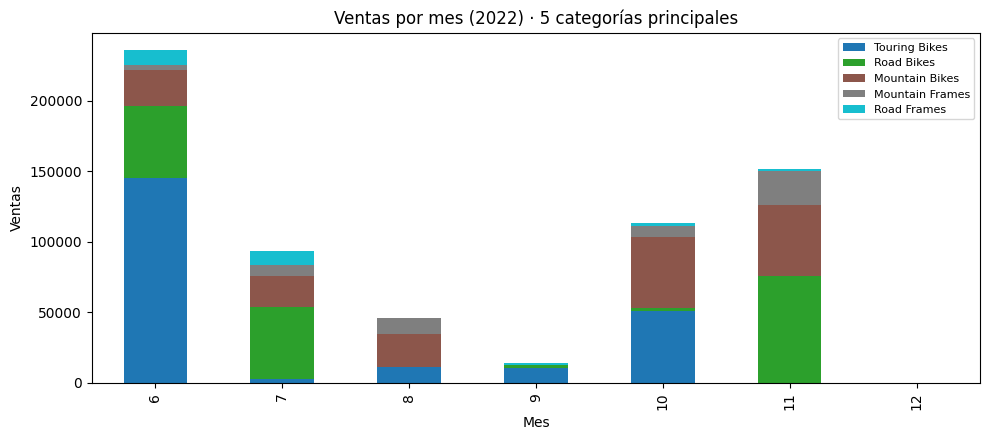

In [9]:
por_mes = ventas_mensuales.pivot_table(index='MonthNo', columns='Category', values='Ventas', aggfunc='sum').fillna(0)
top = por_mes.sum().sort_values(ascending=False).head(5).index
ax = por_mes[top].plot(kind='bar', stacked=True, figsize=(10, 4.5), colormap='tab10')
ax.set_title('Ventas por mes (2022) · 5 categorías principales'); ax.set_xlabel('Mes'); ax.set_ylabel('Ventas')
ax.legend(fontsize=8, title='')
plt.tight_layout()
plt.savefig('../imagenes/ventas-mensuales-categoria.png', dpi=110, bbox_inches='tight')
plt.show()